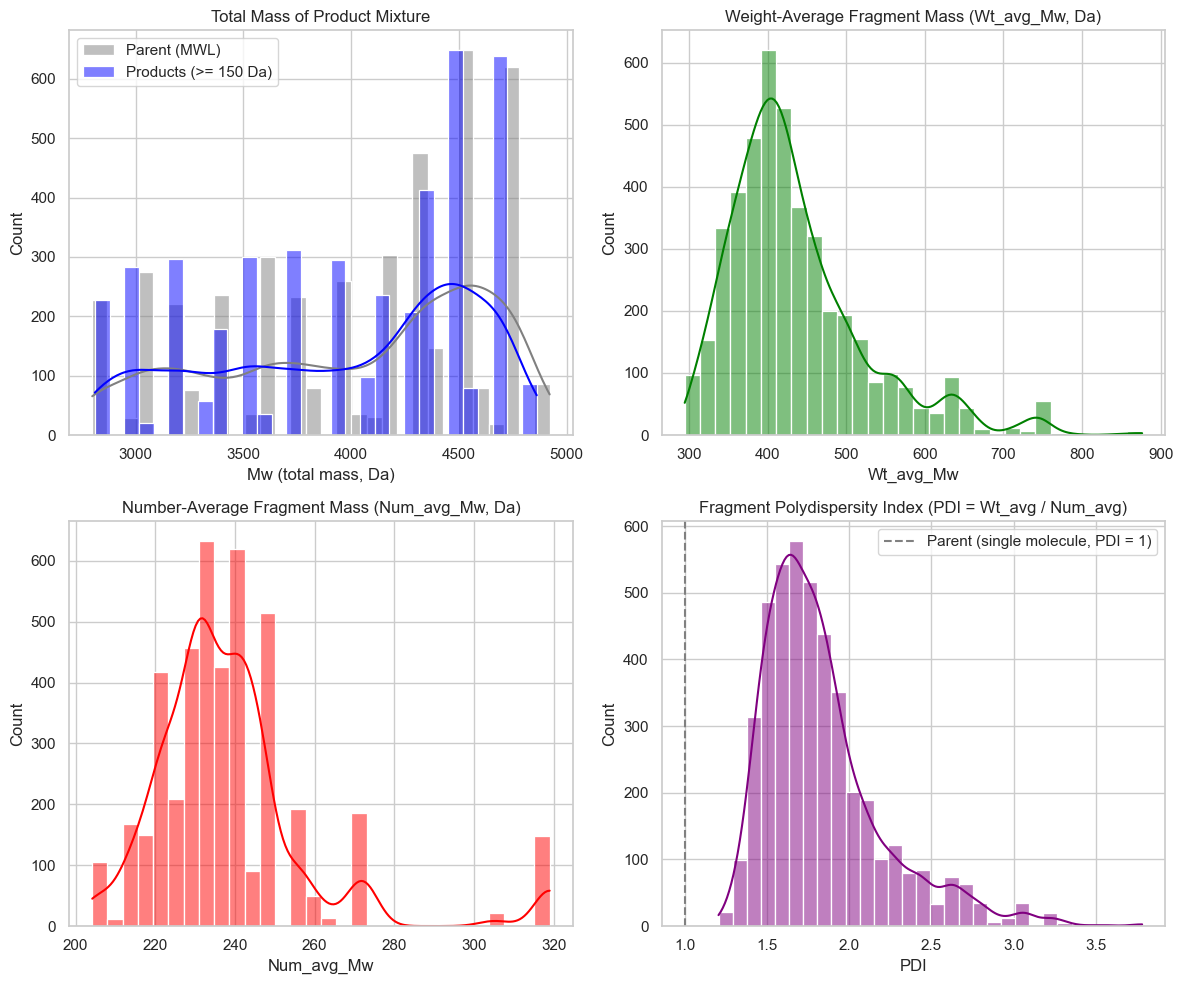

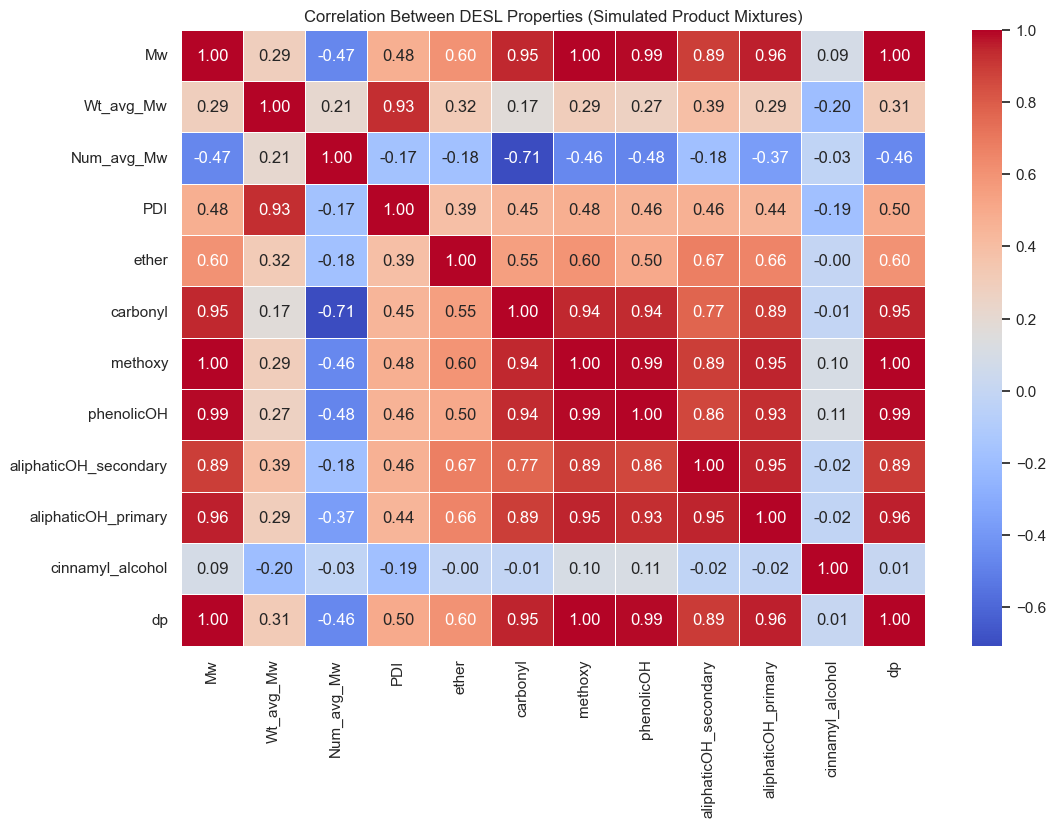

/var/folders/cz/42rd3gxs70n1cr_9pzry1mtr0000gp/T/ipykernel_25230/2647240977.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(data=df_melted, x="Functional Group", y="Count", palette="Set2")


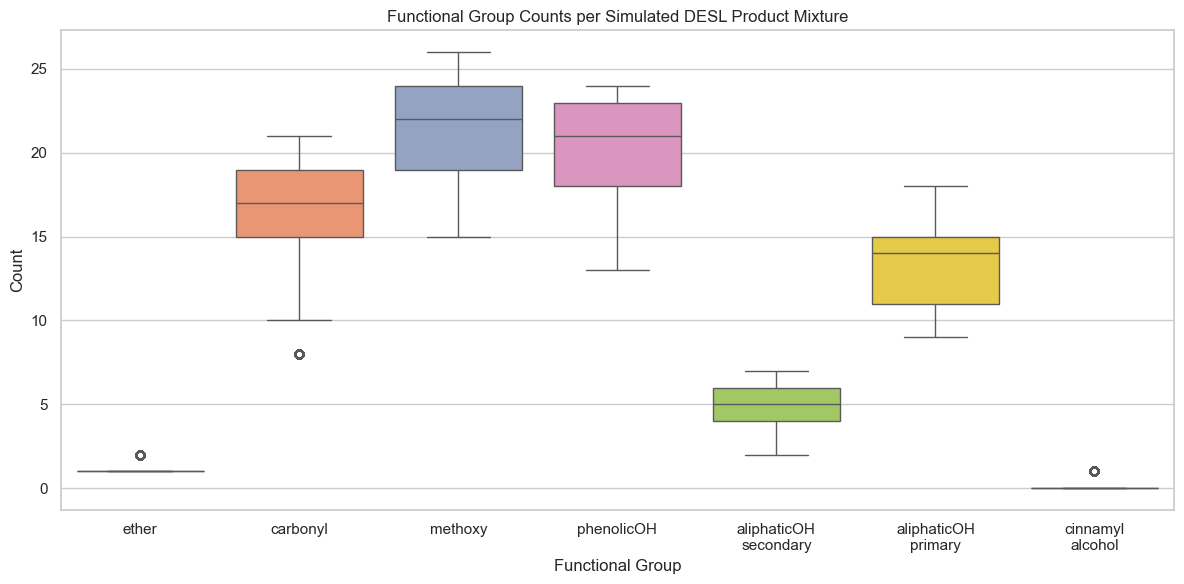

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
file_path = 'datasets/df_data_desl_pathways_dp15_25_cleave90_rings100.csv'  # Replace with your actual file path
df = pd.read_csv(file_path)

# Remove unnamed columns
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

# Mw = total mass of the products at or above the precipitation cutoff (illustrative, not calibrated).
# Kept out of df so the correlation heatmap below is unchanged.
from functools import lru_cache
from rdkit import Chem
from rdkit.Chem import Descriptors

min_precipitate_mw = 150   # Da

@lru_cache(maxsize=None)
def fragment_mass(smiles):
    return Descriptors.ExactMolWt(Chem.MolFromSmiles(smiles))

# Parent structures: the starting chain behind each row (mol/<dp>/<source_file>)
parent_mass = pd.Series([Descriptors.ExactMolWt(Chem.MolFromMolFile(f'mol/{dp}/{name}'))
                         for dp, name in zip(df['dp'], df['source_file'])])

mw_products = pd.Series([
    sum(m for m in (fragment_mass(f) for f in s.split('.')) if m >= min_precipitate_mw)
    for s in df['smiles']
])

# Set plot style
sns.set(style="whitegrid")

# 1. Distribution Plots
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Histogram for Molecular Weight (Mw)
sns.histplot(parent_mass, bins=30, kde=True, ax=axes[0, 0], color='gray', label='Parent (MWL)')
sns.histplot(mw_products, bins=30, kde=True, ax=axes[0, 0], color='blue',
             label=f'Products (>= {min_precipitate_mw} Da)')
axes[0, 0].legend()
axes[0, 0].set_title('Total Mass of Product Mixture')
axes[0, 0].set_xlabel('Mw (total mass, Da)')

# Histogram for Weight-Average Molecular Weight (Wt_avg_Mw)
sns.histplot(df['Wt_avg_Mw'], bins=30, kde=True, ax=axes[0, 1], color='green')
axes[0, 1].set_title(
    'Weight-Average Fragment Mass (Wt_avg_Mw, Da)')

# Histogram for Number-Average Molecular Weight (Num_avg_Mw)
sns.histplot(df['Num_avg_Mw'], bins=30, kde=True, ax=axes[1, 0], color='red')
axes[1, 0].set_title(
    'Number-Average Fragment Mass (Num_avg_Mw, Da)')

# Histogram for Polydispersity Index (PDI)
sns.histplot(df['PDI'], bins=30, kde=True, ax=axes[1, 1], color='purple')
axes[1, 1].set_title('Fragment Polydispersity Index (PDI = Wt_avg / Num_avg)')
axes[1, 1].axvline(1.0, color='gray', linestyle='--', label='Parent (single molecule, PDI = 1)')
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('distribution_plots.png', dpi=300)  # Save as high-resolution image
plt.show()

# 2. Correlation Heatmap
corr_matrix = df.corr(numeric_only=True)
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f",
            cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Between DESL Properties (Simulated Product Mixtures)")
# Save as high-resolution image
plt.savefig('correlation_heatmap.png', dpi=300)
plt.show()

# 3. Functional Group Analysis
functional_groups = ['ether', 'carbonyl', 'methoxy', 'phenolicOH',
                     'aliphaticOH_secondary', 'aliphaticOH_primary', 'cinnamyl_alcohol']

# Melt dataframe for easier plotting
df_melted = df.melt(id_vars=['Mw', 'PDI'], value_vars=functional_groups,
                    var_name="Functional Group", value_name="Count")

# Boxplot: Functional group count distribution
plt.figure(figsize=(12, 6))
ax = sns.boxplot(data=df_melted, x="Functional Group", y="Count", palette="Set2")
# horizontal labels; long names are wrapped at the underscore so they fit
ax.set_xticks(ax.get_xticks())
ax.set_xticklabels([label.get_text().replace('_', '\n') for label in ax.get_xticklabels()],
                   rotation=0, ha='center')
plt.title("Functional Group Counts per Simulated DESL Product Mixture")
plt.tight_layout()  # leave room for the full x-axis labels
plt.savefig('functional_group_distribution.png',
            dpi=300, bbox_inches='tight')  # Save as high-resolution image
plt.show()

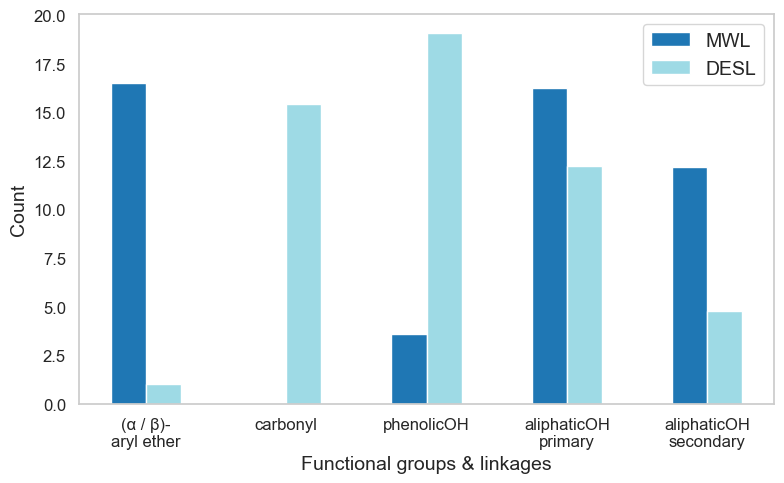

DP = 20 structures: 315
                        MWL  DESL
ether                  16.5   1.0
carbonyl                0.0  15.4
phenolicOH              3.6  19.1
aliphaticOH_primary    16.2  12.2
aliphaticOH_secondary  12.2   4.8


In [2]:
# 4. MWL vs DESL: functional groups and linkages (mean count per chain, DP = 20)
import sys
from pathlib import Path
import numpy as np
from rdkit import Chem, RDLogger

sys.path.insert(0, str(Path('..').resolve()))
from utils.desl_simulation import find_functional_groups_counts

RDLogger.DisableLog('rdApp.*')

groups = ['ether', 'carbonyl', 'phenolicOH', 'aliphaticOH_primary', 'aliphaticOH_secondary']
labels = ['(\u03b1 / \u03b2)-\naryl ether', 'carbonyl', 'phenolicOH',
          'aliphaticOH\nprimary', 'aliphaticOH\nsecondary']

# Figure 6 uses DP = 20 only
df20 = df[df['dp'] == 20]

# MWL = the starting .mol structures behind each row (mol/<dp>/<source_file>)
mwl_rows = []
for dp, name in zip(df20['dp'], df20['source_file']):
    mol = Chem.MolFromMolFile(f'mol/{dp}/{name}')
    mwl_rows.append(find_functional_groups_counts(Chem.MolToSmiles(mol)))
mwl = pd.DataFrame(mwl_rows)

mwl_mean = mwl[groups].mean()
desl_mean = df20[groups].mean()

x = np.arange(len(groups))
width = 0.25
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width / 2, mwl_mean, width, label='MWL', color='#1f77b4')
ax.bar(x + width / 2, desl_mean, width, label='DESL', color='#9edae5')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=12)
ax.set_xlabel('Functional groups & linkages', fontsize=14)
ax.set_ylabel('Count', fontsize=14)
ax.tick_params(axis='y', labelsize=12)
ax.legend(fontsize=14)
ax.grid(False)
plt.tight_layout()
plt.savefig('mwl_vs_desl_functional_groups.png', dpi=300)
plt.show()

print(f'DP = 20 structures: {len(df20)}')
print(pd.DataFrame({'MWL': mwl_mean.round(1), 'DESL': desl_mean.round(1)}))

## TMAP of the unique products in the DESL product mixtures

Every fragment in the `smiles` column is canonicalized, and the unique products are kept with their number of occurrences. The first map below is a TMAP-style tree (minimum spanning tree of Tanimoto distances between Morgan fingerprints, spring layout) that runs in this environment. The interactive map after it uses `tmap` + Faerun with MHFP fingerprints, as in the earlier LGS TMAP: hovering over a point shows the structure, and the properties can be switched as colourings.

In [3]:
# Unique products of the DESL product mixtures and their properties
import sys
import urllib.parse
import numpy as np
from collections import Counter
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, rdMolDescriptors

sys.path.insert(0, '../utils')
from desl_simulation import find_functional_groups_counts   # same functional-group counter as the model

RDLogger.DisableLog('rdApp.*')

counts = Counter()          # how often each product occurs
rows_with = Counter()       # in how many product mixtures it occurs
for mixture in df['smiles']:
    fragments = [Chem.MolToSmiles(Chem.MolFromSmiles(f)) for f in mixture.split('.')]
    counts.update(fragments)
    rows_with.update(set(fragments))

products = list(counts)
mols = [Chem.MolFromSmiles(s) for s in products]
occurrences = np.array([counts[s] for s in products])
masses = np.array([Descriptors.ExactMolWt(m) for m in mols])
groups = [find_functional_groups_counts(s) for s in products]

def mass_class(mass):
    if mass < 150:
        return '1  Small coproduct (<150 Da)'
    if mass < 300:
        return '2  Monomer-sized (150-300 Da)'
    if mass < 1000:
        return '3  Oligomer (300-1000 Da)'
    return '4  Large residue (>=1000 Da)'

product_class = [mass_class(m) for m in masses]
print(f'{len(products)} unique products from {len(df)} product mixtures ({int(occurrences.sum())} fragments)')

433 unique products from 4411 product mixtures (76565 fragments)


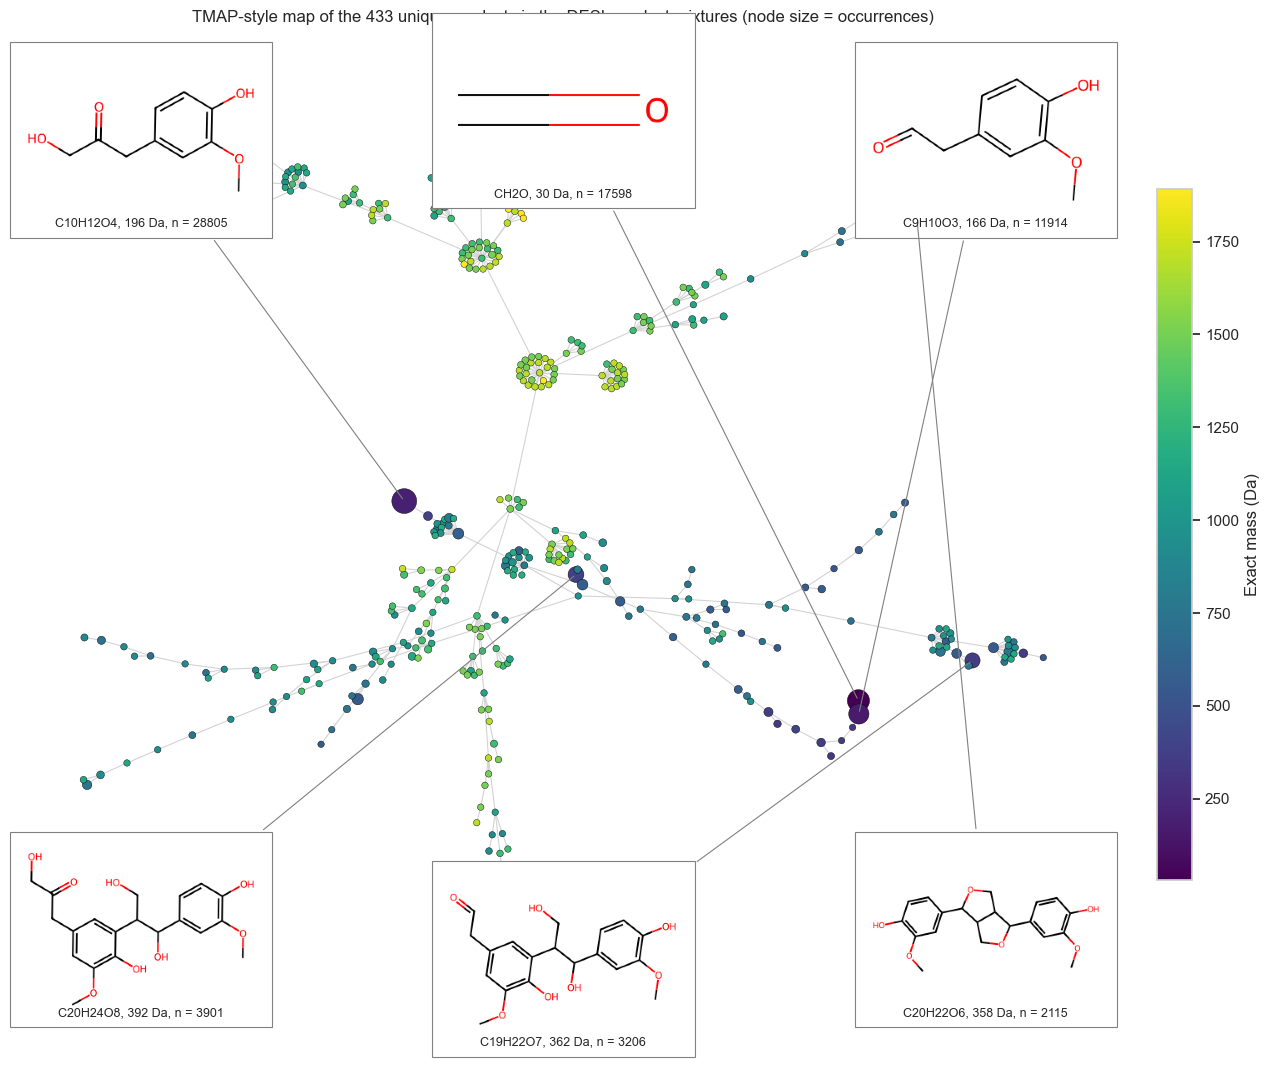

In [4]:
# TMAP-style map (minimum spanning tree of Tanimoto distances) with the most frequent structures
from matplotlib.collections import LineCollection
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from scipy.sparse.csgraph import minimum_spanning_tree
from rdkit import DataStructs
from rdkit.Chem import Draw, rdFingerprintGenerator

generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fingerprints = [generator.GetFingerprint(m) for m in mols]
distance = np.array([1.0 - np.array(DataStructs.BulkTanimotoSimilarity(fp, fingerprints)) for fp in fingerprints]) + 1e-6
np.fill_diagonal(distance, 0.0)
tree = minimum_spanning_tree(distance).tocoo()
edges = list(zip(tree.row, tree.col))

def tree_layout(edges, n, iterations=400, seed=1):
    """Fruchterman-Reingold spring layout of the tree (deterministic for a fixed seed)."""
    rng = np.random.default_rng(seed)
    pos = rng.uniform(-1, 1, size=(n, 2))
    k = 2.0 / np.sqrt(n)
    temperature = 0.1
    for _ in range(iterations):
        delta = pos[:, None, :] - pos[None, :, :]
        dist = np.linalg.norm(delta, axis=-1) + 1e-9
        disp = (delta / dist[..., None] * (k ** 2 / dist)[..., None]).sum(axis=1)
        for a, b in edges:
            d = pos[a] - pos[b]
            length = np.linalg.norm(d) + 1e-9
            force = d / length * (length ** 2 / k)
            disp[a] -= force
            disp[b] += force
        length = np.linalg.norm(disp, axis=1)[:, None] + 1e-9
        pos += disp / length * np.minimum(length, temperature)
        temperature = max(temperature * 0.99, 0.002)
    return pos

positions = tree_layout(edges, len(products))

fig, ax = plt.subplots(figsize=(14, 11))
ax.add_collection(LineCollection([[positions[a], positions[b]] for a, b in edges],
                                 colors='lightgray', linewidths=0.8, zorder=1))
points = ax.scatter(positions[:, 0], positions[:, 1], c=masses, cmap='viridis',
                    s=20 + 300 * np.sqrt(occurrences / occurrences.max()),
                    edgecolors='black', linewidths=0.3, zorder=2)
ax.autoscale_view()

# structures of the six most frequent products in fixed boxes around the map (no overlap)
anchors = [(0.10, 0.90), (0.50, 0.93), (0.90, 0.90), (0.10, 0.10), (0.50, 0.07), (0.90, 0.10)]
for i, anchor in zip(np.argsort(occurrences)[::-1][:6], anchors):
    image = Draw.MolToImage(mols[i], size=(300, 220))
    box = AnnotationBbox(OffsetImage(np.asarray(image), zoom=0.6), positions[i], xybox=anchor,
                         xycoords='data', boxcoords='axes fraction', frameon=True, zorder=4,
                         bboxprops=dict(ec='gray', lw=0.8),
                         arrowprops=dict(arrowstyle='-', color='gray', lw=0.8))
    ax.add_artist(box)
    ax.annotate(f'{rdMolDescriptors.CalcMolFormula(mols[i])}, {masses[i]:.0f} Da, n = {occurrences[i]}',
                anchor, xycoords='axes fraction', xytext=(0, -62), textcoords='offset points',
                fontsize=9, ha='center', zorder=5)
fig.colorbar(points, ax=ax, label='Exact mass (Da)', shrink=0.7)
ax.set_title(f'TMAP-style map of the {len(products)} unique products in the DESL product mixtures (node size = occurrences)',
             pad=14)
ax.axis('off')
plt.tight_layout()
plt.savefig('tmap_unique_products.png', dpi=300, bbox_inches='tight')
plt.show()

## Interactive ChemPlot map of the unique products (structure on hover)

[ChemPlot](https://github.com/mcsorkun/ChemPlot) describes each unique product by its Morgan fingerprint (`sim_type='structural'`), projects the products to two dimensions with t-SNE and draws an interactive Bokeh plot. Hovering over a point shows the structure, the SMILES and the colouring value. Unlike `tmap`, ChemPlot installs in the project's `venv`. The maps are also saved as HTML files in `charts/`. The number of occurrences of each product is not shown on hover; it is the node size on the TMAP-style map above.

In [ ]:
# Interactive ChemPlot maps of the unique products: hover over a point to see the structure
import warnings
from pathlib import Path
from bokeh.io import output_notebook, show
from chemplot import Plotter

warnings.filterwarnings('ignore')
output_notebook()
Path('charts').mkdir(exist_ok=True)

# 1) coloured by exact mass (regression-type target)
cp_mass = Plotter.from_smiles(products, target=masses.tolist(), target_type='R', sim_type='structural')
cp_mass.tsne(random_state=0)
title_mass = 'Unique DESL products: exact mass (Da)'
cp_mass.interactive_plot(show_plot=False, title=title_mass,
                         filename='charts/chemplot_unique_products_mass.html')   # saves the HTML file
show(cp_mass.interactive_plot(show_plot=False, title=title_mass))                 # a second figure for display

In [ ]:
# 2) coloured by product class (classification-type target)
cp_class = Plotter.from_smiles(products, target=product_class, target_type='C', sim_type='structural')
cp_class.tsne(random_state=0)
title_class = 'Unique DESL products: product class'
cp_class.interactive_plot(show_plot=False, title=title_class,
                          filename='charts/chemplot_unique_products_class.html')
show(cp_class.interactive_plot(show_plot=False, title=title_class))